# 03 · Q5 — Biết thêm quỹ đạo có giúp ước lượng đường kính tiểu hành tinh?

Khi chưa đo được đường kính và chưa biết suất phản chiếu, thông tin quỹ đạo có giúp ước lượng đường kính chính xác hơn so với chỉ biết độ sáng tuyệt đối H? Nếu có, sai số giảm bao nhiêu km?

Người sử dụng là người nghiên cứu cần ước lượng kích thước ban đầu cho một vật thể đã có thông tin trong danh mục. Đây là hồi quy với biến đích `diameter` (km). Q2 khảo sát các vật thể đã đo. Q5 giấu đường kính của các vật thể test để đánh giá dự đoán trên vật thể chưa thấy lúc huấn luyện.

Chạy trong môi trường `asteroid-pds` từ thư mục gốc hoặc `notebooks/`. Đặt CSV theo hướng dẫn Notebook 01 ở `data/raw/dataset.csv`. Chọn **Restart Kernel and Run All**. Phần cuối dành cho nhóm tự đọc số liệu và viết kết luận theo mục 6 của đề.

## 1. Đầu vào và chất lượng mẫu

| Vai trò | Cột | Lý do |
|---|---|---|
| A | `H` | Độ sáng tuyệt đối có ở thời điểm dự đoán |
| B | `H, a, e, i, class` | Thêm bán trục lớn (au), độ lệch tâm, độ nghiêng (độ) và lớp quỹ đạo |
| Đích | `diameter` | Giữ số đo hữu hạn, dương |
| Định danh | `spkid` | Kiểm tra trùng, chia theo vật thể và tra sai số |

Chỉ đưa đúng các cột A hoặc B vào mô hình. Loại `albedo` vì giả định chưa biết. Loại `diameter_sigma` và mọi biến tạo từ đường kính vì dựa vào phép đo chưa có. ID, tên và các cột còn lại nằm ngoài thiết kế.

Đọc cùng CSV như Notebook 02, chọn đúng các cột cần dùng để giảm bộ nhớ. Bỏ bản sao giống nhau trên các cột Q5 và bản ghi thiếu mã vật thể. Giữ các phép ghi khác nhau của cùng vật thể nếu có và chia theo mã. Sau khi đổi cột số, giá trị vô hạn được coi là thiếu. Các dòng có H hợp lệ nhưng thiếu đường kính được dùng để khảo sát phạm vi áp dụng.

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
ORBIT = ["a", "e", "i", "class"]
FEATURES = {"A": ["H"], "B": ["H", *ORBIT]}
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
data_path = root / "data" / "raw" / "dataset.csv"
if not data_path.is_file():
    raise FileNotFoundError(f"Đặt CSV theo Notebook 01 tại {data_path}")

df = pd.read_csv(data_path, usecols=["spkid", "diameter", *FEATURES["B"]],
                 dtype={"spkid": str, "class": str}, low_memory=False)
counts = [("Đọc CSV", len(df))]
for col in ["diameter", "H", "a", "e", "i"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
df["spkid"] = df["spkid"].str.strip().replace("", np.nan)
df["class"] = df["class"].str.strip().replace("", np.nan)
df = df.drop_duplicates()
counts.append(("Bỏ bản sao trên các cột Q5", len(df)))
df = df.dropna(subset=["spkid"])
counts.append(("Có mã vật thể", len(df)))
no_diameter = df.loc[df["diameter"].isna() & df["H"].notna(), ["spkid", "H", "class"]]
measured = df.loc[df["diameter"].gt(0)]
counts.append(("Đường kính hợp lệ", len(measured)))
sample = measured.dropna(subset=["H"]).reset_index(drop=True)
counts.append(("Có thêm H hợp lệ", len(sample)))
audit = pd.DataFrame(counts, columns=["Bước", "Số dòng"])
audit["Số dòng bỏ"] = -audit["Số dòng"].diff().fillna(0).astype(int)
display(audit, sample[ORBIT].isna().sum().rename("Số dòng thiếu quỹ đạo").to_frame())
print(f"{sample['spkid'].nunique():,} vật thể có nhãn từ {len(sample):,} dòng.")

,Bước,Số dòng,Số dòng bỏ
0,Đọc CSV,958524,0
1,Bỏ bản sao trên các cột Q5,958524,0
2,Có mã vật thể,958524,0
3,Đường kính hợp lệ,136209,822315
4,Có thêm H hợp lệ,132045,4164


,Số dòng thiếu quỹ đạo
a,0
e,0
i,0
class,0


132,045 vật thể có nhãn từ 132,045 dòng.


## 2. Chia dữ liệu và xác thực chéo

Giữ khoảng 20% vật thể làm test và cố định seed. Mục tiêu là dự đoán vật thể khác trong cùng danh mục. Nếu mã lặp, dùng GroupShuffleSplit và GroupKFold để các dòng của một vật thể luôn đi cùng nhau. Nếu mã duy nhất, chia ngẫu nhiên và dùng KFold xáo trộn. Dùng chung các fold và tập test cho cả A và B.

In [10]:
groups = sample["spkid"]
indices = np.arange(len(sample))
if groups.is_unique:
    train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=SEED)
    folds = list(KFold(n_splits=3, shuffle=True, random_state=SEED).split(train_idx))
else:
    split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    train_idx, test_idx = next(split.split(indices, groups=groups))
    folds = list(GroupKFold(n_splits=3).split(train_idx, groups=groups.iloc[train_idx]))

train, test = sample.iloc[train_idx], sample.iloc[test_idx]
assert set(train["spkid"]).isdisjoint(test["spkid"])
for fit_idx, valid_idx in folds:
    assert set(train.iloc[fit_idx]["spkid"]).isdisjoint(train.iloc[valid_idx]["spkid"])
y_train, y_test = train["diameter"], test["diameter"]
display(pd.DataFrame({
    "Tập": ["Train", "Test"],
    "Số dòng": [len(train), len(test)],
    "Số vật thể": [train["spkid"].nunique(), test["spkid"].nunique()],
}))

,Tập,Số dòng,Số vật thể
0,Train,105636,105636
1,Test,26409,26409


## 3. Mốc so sánh, pipeline và tinh chỉnh

- Mốc đơn giản dự đoán trung vị đường kính tập train. Trung vị tối thiểu hóa tổng sai số tuyệt đối đối với dự đoán hằng số.
- Ridge kiểm tra quan hệ tuyến tính trên log đường kính và dùng điều chuẩn L2. Cây tăng cường kiểm tra quan hệ phi tuyến và tương tác giữa các biến.
- Pipeline điền trung vị cho cột số, dùng một nhãn riêng cho class thiếu và one-hot cho class. Ridge chuẩn hóa cột số. Mỗi lần fit, các bước tiền xử lý chỉ thấy phần train được cấp.
- Cả Ridge và cây học trên log đường kính. Dự đoán được đổi ngược về km trước khi tính MAE. MAE là sai lệch tuyệt đối trung bình theo km. Trung vị sai số tuyệt đối bổ sung góc nhìn về trường hợp điển hình.
- Dùng CV ba fold với lưới nhỏ. Chọn trước họ mô hình chính theo MAE CV thấp nhất của **phương án B**, sau đó khóa lựa chọn trước khi chấm test. Giới hạn số luồng để chạy ổn định trên máy cá nhân.

In [11]:
def make_estimator(model, columns):
    numeric = [col for col in columns if col != "class"]
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if isinstance(model, Ridge):
        num_steps.append(("scale", StandardScaler()))
    transformers = [("numeric", Pipeline(num_steps), numeric)]
    if "class" in columns:
        categories = Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Thiếu")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ])
        transformers.append(("class", categories, ["class"]))
    preprocess = ColumnTransformer(transformers)
    pipe = Pipeline([("preprocess", preprocess), ("model", model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)

specs = {
    "Ridge": (Ridge(), {"regressor__model__alpha": [0.1, 1, 10, 100]}),
    "Cây tăng cường": (
        HistGradientBoostingRegressor(
            loss="absolute_error", max_iter=200, early_stopping=False, random_state=SEED
        ),
        {"regressor__model__max_leaf_nodes": [7, 15, 31]},
    ),
}
baseline = Pipeline([("model", DummyRegressor(strategy="median"))])
baseline.fit(train[FEATURES["A"]], y_train)

searches = {}
cv_rows = []
with threadpool_limits(limits=2):
    for family, (model, grid) in specs.items():
        for variant, columns in FEATURES.items():
            search = GridSearchCV(
                make_estimator(model, columns), grid, cv=folds,
                scoring="neg_mean_absolute_error", n_jobs=1, error_score="raise",
            )
            search.fit(train[columns], y_train)
            searches[family, variant] = search
            cv_rows.append((family, variant, -search.best_score_, search.best_params_))
cv_table = pd.DataFrame(cv_rows, columns=["Họ mô hình", "Đầu vào", "MAE CV (km)", "Tham số"])
main_family = cv_table.loc[cv_table["Đầu vào"].eq("B")].sort_values(
    "MAE CV (km)", kind="stable"
).iloc[0]["Họ mô hình"]
display(cv_table)
print("Họ mô hình chính, chọn bằng CV:", main_family)

,Họ mô hình,Đầu vào,MAE CV (km),Tham số
0,Ridge,A,1.755141e+00,{'regressor__model__alpha': 0.1}
1,Ridge,B,8.753059e+25,{'regressor__model__alpha': 100}
2,Cây tăng cường,A,1.632271e+00,{'regressor__model__max_leaf_nodes': 7}
3,Cây tăng cường,B,1.100753e+00,{'regressor__model__max_leaf_nodes': 31}


Họ mô hình chính, chọn bằng CV: Cây tăng cường


## 4. Đánh giá trên test

Dự đoán một lần bằng từng mô hình đã chọn. Mức giảm là MAE A trừ MAE B, nên dấu dương có lợi cho B. Bootstrap theo vật thể giữ các lỗi của A và B theo cặp. Khi có nhiều dòng mỗi mã, lấy lại mẫu theo cụm và tính MAE theo dòng. Khoảng 95% phản ánh bất định của mẫu test với các mô hình đã huấn luyện cố định.

Mốc trung vị: 2.8341 km | Test: 26,409 vật thể


,A: chỉ dùng H (km),B: H + quỹ đạo (km)
Phương pháp,,
Baseline trung vị,2.8341,2.8341
Ridge,1.7643,17.3057
Cây tăng cường,1.6491,1.1073


,MAE A (km),MAE B (km),Giảm MAE (km),Giảm MAE (%),CI 95% dưới (km),CI 95% trên (km),MedAE A (km),MedAE B (km)
Họ mô hình,,,,,,,,
Ridge,1.7643,17.3057,-15.5414,-880.8674,-46.7629,0.1322,1.2141,1.0882
Cây tăng cường,1.6491,1.1073,0.5419,32.8570,0.5243,0.5587,1.1110,0.5264


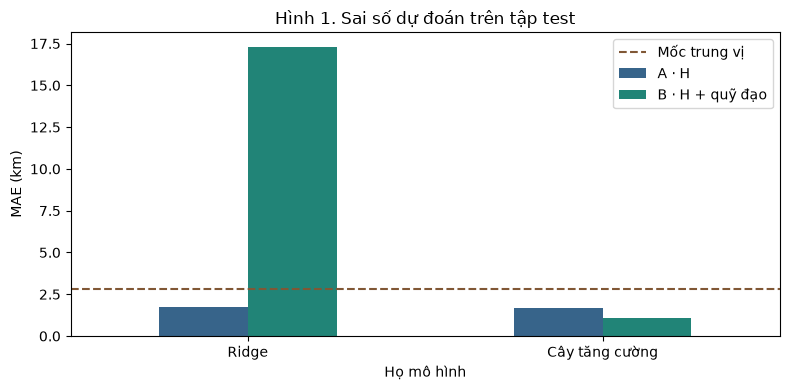

In [12]:
pred = test[["spkid", "H", "class", "diameter"]].reset_index(drop=True)
pred["baseline_km"] = baseline.predict(test[FEATURES["A"]])
baseline_mae = mean_absolute_error(pred["diameter"], pred["baseline_km"])
prediction_columns = {}
score_rows = []
rng = np.random.default_rng(SEED)
with threadpool_limits(limits=2):
    for family, slug in [("Ridge", "ridge"), ("Cây tăng cường", "boosting")]:
        abs_errors = {}
        for variant, columns in FEATURES.items():
            name = f"{slug}_{variant}_km"
            prediction_columns[family, variant] = name
            pred[name] = searches[family, variant].predict(test[columns])
            abs_errors[variant] = (pred[name] - pred["diameter"]).abs()
        mae_a, mae_b = (abs_errors[k].mean() for k in ("A", "B"))
        delta = mae_a - mae_b
        by_object = (abs_errors["A"] - abs_errors["B"]).groupby(pred["spkid"]).agg(
            ["sum", "size"]
        )
        sums, sizes = by_object["sum"].to_numpy(), by_object["size"].to_numpy()
        replicates = []
        for _ in range(1000):
            draw = rng.integers(len(sums), size=len(sums))
            replicates.append(sums[draw].sum() / sizes[draw].sum())
        lo, hi = np.quantile(replicates, [0.025, 0.975])
        score_rows.append((family, mae_a, mae_b, delta,
                           100 * delta / mae_a if mae_a else np.nan, lo, hi,
                           abs_errors["A"].median(), abs_errors["B"].median()))

scores = pd.DataFrame(score_rows, columns=[
    "Họ mô hình", "MAE A (km)", "MAE B (km)", "Giảm MAE (km)", "Giảm MAE (%)",
    "CI 95% dưới (km)", "CI 95% trên (km)", "MedAE A (km)", "MedAE B (km)",
]).set_index("Họ mô hình")
print(f"Mốc trung vị: {baseline_mae:.4f} km | Test: {pred['spkid'].nunique():,} vật thể")
# So sánh cả ba phương pháp trên cùng tập test
bang_mae = scores[["MAE A (km)", "MAE B (km)"]].copy()
bang_mae.loc["Baseline trung vị"] = [baseline_mae, baseline_mae]
bang_mae = bang_mae.loc[["Baseline trung vị", "Ridge", "Cây tăng cường"]]
bang_mae.columns = ["A: chỉ dùng H (km)", "B: H + quỹ đạo (km)"]
bang_mae.index.name = "Phương pháp"
display(bang_mae.round(4))

# Giữ bảng chi tiết để đọc mức giảm MAE và khoảng tin cậy
display(scores.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
scores[["MAE A (km)", "MAE B (km)"]].rename(columns={
    "MAE A (km)": "A · H", "MAE B (km)": "B · H + quỹ đạo",
}).plot.bar(ax=ax, rot=0, color=["#37648a", "#218477"])
ax.axhline(baseline_mae, color="#805735", linestyle="--", label="Mốc trung vị")
ax.set(title="Hình 1. Sai số dự đoán trên tập test", xlabel="Họ mô hình", ylabel="MAE (km)")
ax.legend()
fig.tight_layout()
plt.show()

## 5. Sai số theo khoảng đường kính và trường hợp cụ thể

Dùng các khoảng đường kính thật cố định để mô tả sai số sau dự đoán. So sánh hai cách trong họ mô hình chính. Sai số dương có nghĩa dự đoán lớn hơn số đo. Cỡ mẫu từng khoảng và từng lớp giúp đánh giá độ ổn định của các chênh lệch.

,n,n_objects,MAE_A,MAE_B,bias_A,bias_B
Khoảng đường kính,,,,,,
Dưới 1,128,128,0.522,0.267,0.411,0.158
1–<5,17081,17081,0.911,0.573,0.620,0.182
5–<20,8679,8679,2.248,1.305,-1.266,-0.662
Từ 20,521,521,16.142,15.532,-6.607,-7.106


,n,n_objects,MAE_A,MAE_B,bias_A,bias_B,Giảm MAE (km)
class,,,,,,,
MBA,24227,24227,1.548,1.059,0.016,-0.234,0.489
OMB,1470,1470,2.529,1.430,-2.099,-0.177,1.099
TJN,374,374,4.023,2.471,-2.976,-0.022,1.552
IMB,96,96,2.289,0.394,2.281,-0.067,1.895
APO,92,92,0.646,0.357,0.410,-0.099,0.289
MCA,61,61,1.481,0.904,0.785,-0.353,0.577
AMO,60,60,0.913,0.620,0.300,-0.152,0.293
ATE,17,17,0.490,0.265,0.432,0.073,0.225
CEN,8,8,36.369,36.909,-25.674,-29.655,-0.540


,spkid,H,class,diameter,boosting_B_km,error_B_km
12377,2000670,9.4,MBA,35.886,110.146415,74.260415
628,2001102,9.4,MBA,36.632,95.408702,58.776702
23412,2000482,8.9,MBA,45.751,103.667865,57.916865
14991,2000701,9.2,MBA,42.943,100.300345,57.357345
23570,2000863,9.1,OMB,38.724,94.567280,55.843280


,spkid,H,class,diameter,boosting_B_km,error_B_km
6984,2000001,3.4,MBA,939.400,82.905356,-856.494644
25274,2000511,6.3,MBA,270.327,90.883679,-179.443321
13859,2000087,6.8,OMB,253.051,94.347667,-158.703333
926,2095626,6.9,CEN,230.500,86.555136,-143.944864
1209,2000088,7.2,MBA,232.000,96.721353,-135.278647


,spkid,H,a,e,i,class,diameter,Họ mô hình,Dự đoán B (km),Sai số tuyệt đối (km),Phần trăm tổng sai số
0,2336756,10.6,281.1747,0.9666,140.7308,TNO,44.200,Ridge,410958.1515,410913.9515,89.9103
1,3517549,13.2,170.0708,0.9683,99.8973,TNO,15.900,Ridge,2816.0147,2800.1147,0.6127
2,2000001,3.4,2.7692,0.0760,10.5941,MBA,939.400,Ridge,289.8170,649.5830,0.1421
3,2000001,3.4,2.7692,0.0760,10.5941,MBA,939.400,Cây tăng cường,82.9054,856.4946,2.9290
4,2000511,6.3,3.1648,0.1881,15.9390,MBA,270.327,Cây tăng cường,90.8837,179.4433,0.6136
5,2000087,6.8,3.4821,0.0934,10.8760,OMB,253.051,Cây tăng cường,94.3477,158.7033,0.5427


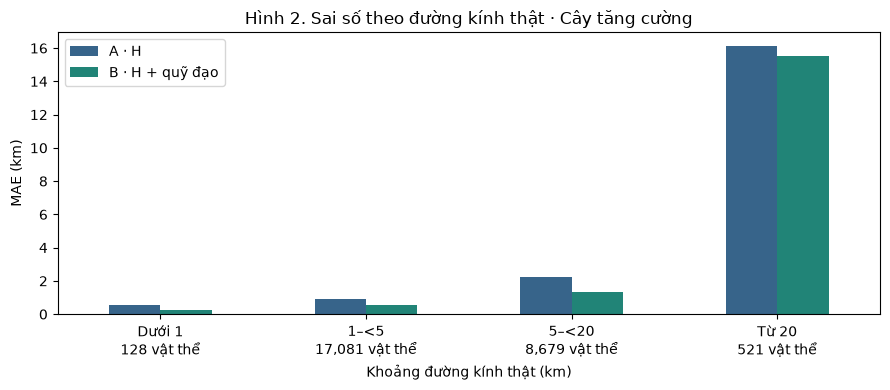

Đã ghi dự đoán test: data/processed/q5_test_predictions.csv


In [19]:
for variant in FEATURES:
    pred[f"error_{variant}_km"] = pred[prediction_columns[main_family, variant]] - pred["diameter"]
    pred[f"abs_{variant}_km"] = pred[f"error_{variant}_km"].abs()
pred["Khoảng đường kính"] = pd.cut(
    pred["diameter"], bins=[0, 1, 5, 20, np.inf],
    labels=["Dưới 1", "1–<5", "5–<20", "Từ 20"], right=False,
)
error_summary = dict(
    n=("diameter", "size"), n_objects=("spkid", "nunique"),
    MAE_A=("abs_A_km", "mean"), MAE_B=("abs_B_km", "mean"),
        bias_A=("error_A_km", "mean"),
        bias_B=("error_B_km", "mean"),
)
by_size = pred.groupby("Khoảng đường kính", observed=True).agg(**error_summary)
by_class = pred.groupby("class", dropna=False).agg(**error_summary)
by_class["Giảm MAE (km)"] = by_class["MAE_A"] - by_class["MAE_B"]
display(by_size.round(3), by_class.sort_values("n", ascending=False).round(3))
examples = ["spkid", "H", "class", "diameter", prediction_columns[main_family, "B"], "error_B_km"]
display(pred.nlargest(5, "error_B_km")[examples],
        pred.nsmallest(5, "error_B_km")[examples])

# So sánh ca sai lớn nhất của từng mô hình B, kể cả họ không được chọn chính.
worst_cases = []
for family in specs:
    predicted = prediction_columns[family, "B"]
    diagnostics = test[["spkid", "H", *ORBIT, "diameter"]].reset_index(drop=True)
    diagnostics["Họ mô hình"] = family
    diagnostics["Dự đoán B (km)"] = pred[predicted]
    diagnostics["Sai số tuyệt đối (km)"] = (pred[predicted] - pred["diameter"]).abs()
    total_error = diagnostics["Sai số tuyệt đối (km)"].sum()
    worst = diagnostics.nlargest(3, "Sai số tuyệt đối (km)").copy()
    worst["Phần trăm tổng sai số"] = (
        100 * worst["Sai số tuyệt đối (km)"] / total_error if total_error else 0
    )
    worst_cases.append(worst)
display(pd.concat(worst_cases, ignore_index=True).round(4))

labels = [f"{band}\n{count:,} vật thể" for band, count in by_size["n_objects"].items()]
fig, ax = plt.subplots(figsize=(9, 4))
by_size.set_axis(labels)[["MAE_A", "MAE_B"]].rename(columns={
    "MAE_A": "A · H", "MAE_B": "B · H + quỹ đạo",
}).plot.bar(ax=ax, rot=0, color=["#37648a", "#218477"])
ax.set(title=f"Hình 2. Sai số theo đường kính thật · {main_family}",
       xlabel="Khoảng đường kính thật (km)", ylabel="MAE (km)")
fig.tight_layout()
plt.show()

output_dir = root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)
output = output_dir / "q5_test_predictions.csv"
pred.to_csv(output, index=False)
print(f"Đã ghi dự đoán test: {output.relative_to(root)}")

### Vì sao một số sai số ở mục 5 lớn?

Hai bảng đầu khảo sát trường hợp Ridge B dự đoán sai nhiều nhất. Bảng 1 đối chiếu
quỹ đạo của vật thể 2336756 với phân bố trong tập train. Bảng 2 tính lại MAE khi
tạm bỏ riêng vật thể này để đo mức ảnh hưởng. Kết quả chính ở mục 4 vẫn dùng
toàn bộ tập test.

Bảng 3 xét riêng các vật thể có đường kính thật từ 20 km trở lên. Với từng
phương án A và B, bảng liệt kê các vật thể đóng góp nhiều nhất vào MAE hoặc bị
đoán thiếu nhiều nhất. Đóng góp vào bias mang dấu âm khi mô hình đoán thiếu.

In [20]:
# 1. So sánh quỹ đạo của vật thể 2336756 với tập train
object_id = "2336756"
orbit_cols = ["a", "e", "i"]

orbit_table = train[orbit_cols].quantile([0.50, 0.99, 1.00]).T
orbit_table.columns = ["Trung vị train", "Phân vị 99% train", "Lớn nhất train"]
target = test.loc[test["spkid"].astype(str).eq(object_id), orbit_cols]
assert len(target) == 1, f"Cần đúng một bản ghi test cho vật thể {object_id}."
orbit_table[f"Vật thể {object_id}"] = target.iloc[0]

print("1. Quỹ đạo của vật thể có sai số Ridge B lớn nhất")
display(orbit_table.round(3))


# 2. Đo ảnh hưởng của vật thể đó lên MAE, dùng cùng mẫu cho mọi phương pháp
is_target = pred["spkid"].astype(str).eq(object_id)
assert is_target.sum() == 1, "Kiểm tra lại mã vật thể trong bảng dự đoán."

methods = {
    "Baseline trung vị": "baseline_km",
    "Ridge A": "ridge_A_km",
    "Ridge B": "ridge_B_km",
    "Cây tăng cường A": "boosting_A_km",
    "Cây tăng cường B": "boosting_B_km",
}

sensitivity_rows = []
for method, col in methods.items():
    abs_error = (pred[col] - pred["diameter"]).abs()
    full_mae = abs_error.mean()
    remaining_mae = abs_error.loc[~is_target].mean()
    sensitivity_rows.append({
        "Phương pháp": method,
        "MAE toàn bộ test": full_mae,
        "MAE khi bỏ 2336756": remaining_mae,
        "Mức giảm MAE": full_mae - remaining_mae,
    })

print(f"\n2. MAE (km) trên {len(pred):,} bản ghi và khi bỏ riêng vật thể {object_id}")
display(pd.DataFrame(sensitivity_rows).set_index("Phương pháp").round(4))


# 3. Tìm các vật thể ảnh hưởng nhiều đến MAE và bias trong nhóm từ 20 km
# Dùng toàn bộ nhóm, kể cả 2336756 nếu vật thể đó thuộc nhóm này.
large = pred.loc[pred["diameter"] >= 20]
n = len(large)
assert n > 0, "Tập test không có vật thể nào có đường kính từ 20 km."

case_tables = []
for variant in ["A", "B"]:
    col = prediction_columns[main_family, variant]
    cases = large[["spkid", "class", "diameter", col]].copy()
    cases.columns = ["Mã vật thể", "Lớp", "Đường kính thật", "Dự đoán"]
    error = cases["Dự đoán"] - cases["Đường kính thật"]

    cases["Phương án"] = variant
    cases["Sai số có dấu"] = error
    cases["Đóng góp vào MAE"] = error.abs() / n
    cases["Đóng góp vào bias"] = error / n

    top_mae = cases.nlargest(5, "Đóng góp vào MAE")
    under = cases.loc[error < 0].nsmallest(5, "Sai số có dấu")

    # Một vật thể có thể thuộc cả hai danh sách. Chỉ hiện một dòng và ghi rõ lý do.
    selected = cases.loc[cases.index.isin(top_mae.index.union(under.index))].copy()
    selected["Lý do xuất hiện"] = [
        "Cả hai" if idx in top_mae.index and idx in under.index
        else "Top 5 đóng góp vào MAE" if idx in top_mae.index
        else "Top 5 đoán thiếu"
        for idx in selected.index
    ]
    case_tables.append(selected.sort_values("Đóng góp vào MAE", ascending=False))

print(f"\n3. {main_family} · Các trường hợp đáng chú ý trong {n} bản ghi từ 20 km")
print("A = chỉ dùng H | B = H + quỹ đạo | Đường kính và sai số tính bằng km")
display(pd.concat(case_tables).set_index(["Phương án", "Mã vật thể"]).round(3))

1. Quỹ đạo của vật thể có sai số Ridge B lớn nhất


,Trung vị train,Phân vị 99% train,Lớn nhất train,Vật thể 2336756
a,2.762,5.186,376.133,281.175
e,0.140,0.350,0.984,0.967
i,9.190,28.777,170.335,140.731



2. MAE (km) trên 26,409 bản ghi và khi bỏ riêng vật thể 2336756


,MAE toàn bộ test,MAE khi bỏ 2336756,Mức giảm MAE
Phương pháp,,,
Baseline trung vị,2.8341,2.8327,0.0014
Ridge A,1.7643,1.7636,0.0007
Ridge B,17.3057,1.7462,15.5596
Cây tăng cường A,1.6491,1.6488,0.0004
Cây tăng cường B,1.1073,1.1069,0.0003



3. Cây tăng cường · Các trường hợp đáng chú ý trong 521 bản ghi từ 20 km
A = chỉ dùng H | B = H + quỹ đạo | Đường kính và sai số tính bằng km


Lớp  Đường kính thật  Dự đoán  Sai số có dấu  \
Phương án Mã vật thể                                                 
A         2000001     MBA          939.400   93.642       -845.758   
          2000511     MBA          270.327   93.642       -176.685   
          2000087     OMB          253.051   93.642       -159.409   
          2000088     MBA          232.000   93.642       -138.358   
          2095626     CEN          230.500   93.642       -136.858   
B         2000001     MBA          939.400   82.905       -856.495   
          2000511     MBA          270.327   90.884       -179.443   
          2000087     OMB          253.051   94.348       -158.703   
          2095626     CEN          230.500   86.555       -143.945   
          2000088     MBA          232.000   96.721       -135.279   

                      Đóng góp vào MAE  Đóng góp vào bias Lý do xuất hiện  
Phương án Mã vật thể                                                       
A         2000001                1.623             -1.623          Cả hai  
          2000511                0.339             -0.339          Cả hai  
          2000087                0.306             -0.306          Cả hai  
          2000088                0.266             -0.266          Cả hai  
          2095626                0.263             -0.263          Cả hai  
B         2000001                1.644             -1.644          Cả hai  
          2000511                0.344             -0.344          Cả hai  
          2000087                0.305             -0.305          Cả hai  
          2095626                0.276             -0.276          Cả hai  
          2000088                0.260             -0.260          Cả hai

## 6. Mô hình dựa vào quỹ đạo đến đâu?

Giữ H và đường kính thật tại chỗ. Trong mỗi lần lặp, dùng chung một hoán vị cho bốn cột quỹ đạo để giữ quan hệ nội bộ của chúng. So MAE của B sau xáo trộn với MAE B gốc. Đây là chẩn đoán mức phụ thuộc vào khối thông tin quỹ đạo. Hoán vị có thể làm thay đổi quan hệ giữa H và quỹ đạo, nên chỉ số này có ý nghĩa khác với mức giảm MAE khi so A và B.

In [14]:
model_b = searches[main_family, "B"].best_estimator_
x_test_b = test[FEATURES["B"]].copy()
rng = np.random.default_rng(SEED + 1)
mae_b = scores.loc[main_family, "MAE B (km)"]
permutation_deltas = []
with threadpool_limits(limits=2):
    for _ in range(15):
        shuffled = x_test_b.copy()
        order = rng.permutation(len(shuffled))
        shuffled[ORBIT] = x_test_b[ORBIT].iloc[order].set_axis(shuffled.index)

        permutation_deltas.append(mean_absolute_error(y_test, model_b.predict(shuffled)) - mae_b)
print(f"MAE thay đổi trung bình khi xáo trộn quỹ đạo: {np.mean(permutation_deltas):+.4f} km.")
print(f"Độ lệch chuẩn qua các lượt xáo trộn: {np.std(permutation_deltas, ddof=1):.4f} km.")

MAE thay đổi trung bình khi xáo trộn quỹ đạo: +0.8211 km.
Độ lệch chuẩn qua các lượt xáo trộn: 0.0099 km.


## 7. Phạm vi áp dụng và phần kết luận của nhóm

So sánh H và lớp quỹ đạo giữa vật thể có số đo và vật thể thiếu đường kính. Chỉ giữ H hợp lệ cho hai nhóm trong bảng này. Với dữ liệu có mã lặp, bỏ các mã đã có số đo khỏi nhóm thiếu và dùng một bản ghi đại diện mỗi mã cho phần so phân bố.

In [16]:
measured_objects = sample.drop_duplicates("spkid")
missing_objects = no_diameter.loc[
    ~no_diameter["spkid"].isin(measured["spkid"])
].drop_duplicates("spkid")
coverage = {"Có số đo": measured_objects, "Thiếu đường kính": missing_objects}

display(pd.DataFrame({
    label: {"Số vật thể": len(frame), "H Q1": frame["H"].quantile(0.25),
            "H trung vị": frame["H"].median(), "H Q3": frame["H"].quantile(0.75)}
    for label, frame in coverage.items()
}).T)
class_share = pd.DataFrame({
    label: 100 * frame["class"].fillna("Thiếu").value_counts(normalize=True)
    for label, frame in coverage.items()
})
for label, frame in coverage.items():
    if len(frame):
        class_share[label] = class_share[label].fillna(0)
display(class_share.round(2).rename_axis("Lớp quỹ đạo").rename(
    columns=lambda name: f"{name} (%)"
))
display(scores.loc[[main_family]].round(4))

,Số vật thể,H Q1,H trung vị,H Q3
Có số đo,132045.0,14.4,15.2,16.0
Thiếu đường kính,820216.0,16.4,17.1,17.9


,Có số đo (%),Thiếu đường kính (%)
Lớp quỹ đạo,,
AMO,0.20,1.00
APO,0.37,1.49
AST,0.01,0.01
ATE,0.07,0.20
CEN,0.04,0.06
HYA,0.00,0.00
IEO,0.00,0.00
IMB,0.34,2.40
MBA,91.73,89.01


,MAE A (km),MAE B (km),Giảm MAE (km),Giảm MAE (%),CI 95% dưới (km),CI 95% trên (km),MedAE A (km),MedAE B (km)
Họ mô hình,,,,,,,,
Cây tăng cường,1.6491,1.1073,0.5419,32.857,0.5243,0.5587,1.111,0.5264


### Bản nháp kết luận Q5

Số liệu dưới đây theo đầu ra đang lưu. Nghiêm đối chiếu lại với lần chạy chốt và tự hoàn tất các phần trong ngoặc vuông.

**1. Thêm thông tin quỹ đạo giúp dự đoán chính xác hơn bao nhiêu?**

Trên 26.409 vật thể test, cây tăng cường đạt MAE 1,6491 km khi chỉ dùng H và 1,1073 km khi dùng H cùng thông tin quỹ đạo. Mức giảm là 0,5419 km (32,86%), với khoảng tin cậy bootstrap 95% từ 0,5243 đến 0,5587 km.

[Viết một câu trả lời trực tiếp cho Q5. Khoảng tin cậy nằm hoàn toàn phía nào của 0 và điều đó cho biết gì về mức cải thiện trên tập test?]

**2. Kết quả có giống nhau giữa các mô hình và các nhóm đường kính?**

Với Ridge, MAE tăng từ 1,7643 lên 17,3057 km, trong khi MedAE giảm từ 1,2141 xuống 1,0882 km.

[Chọn một hàng trong bảng sai số theo đường kính ở mục 5. Ghi rõ mô hình, khoảng đường kính, số vật thể, MAE A và MAE B. Nêu sai số tăng hay giảm trong nhóm đó.]

**3. Mô hình sử dụng thông tin quỹ đạo đến mức nào?**

Khi giữ nguyên mô hình B và xáo trộn đồng thời bốn cột quỹ đạo, MAE tăng trung bình 0,8211 km. Độ lệch chuẩn qua 15 lượt là 0,0099 km.

[Viết một câu giải thích vì sao dự đoán kém đi khi mỗi vật thể nhận bộ thông tin quỹ đạo của vật thể khác.]

**4. Kết quả áp dụng được cho nhóm nào?**

Trong các vật thể có H hợp lệ, H trung vị là 15,2 ở nhóm đã đo đường kính và 17,1 ở nhóm thiếu đường kính. Tỷ lệ vật thể lớp MCA ở hai nhóm lần lượt là 0,25% và 2,17%.

[Giải thích vì sao chưa thể dùng MAE 1,1073 km làm sai số đã kiểm chứng cho 820.216 vật thể thiếu đường kính. Chú ý nhóm nào có đường kính thật để đối chiếu.]

### Tài liệu

- [Notebook 01 · Nguồn dữ liệu và khảo sát](01_collection_exploration.ipynb)
- [Notebook 02 · Phân tích non-ML](02_analysis.ipynb)
- [Asteroid Dataset trên Kaggle](https://www.kaggle.com/datasets/sakhawat18/asteroid-dataset)
- Bản thiết kế Q5 của nhóm và đề CSC17104, mục 3.3–3.4 và 6.
- [Stroke-Prediction-Analysis](https://github.com/Ddyln/Stroke-Prediction-Analysis) · tham khảo bố cục trình bày quá trình tinh chỉnh và bảng đánh giá.

# Q6 — Độ sáng và quỹ đạo có giúp ước lượng chu kỳ tự quay của tiểu hành tinh?

Khi chưa đo được chu kỳ tự quay, độ sáng tuyệt đối H và thông tin quỹ đạo có giúp ước lượng thời gian một tiểu hành tinh tự quay một vòng không? Với mốc 8 giờ, mô hình chọn đúng bao nhiêu vật thể có chu kỳ từ 8 giờ trở xuống và bỏ sót bao nhiêu?

Đây là bài toán hồi quy với biến đích `rot_per` (giờ), lấy từ dữ liệu NASA/JPL. Q6 dùng số giờ dự đoán để sàng lọc các vật thể có thể tự quay hết một vòng trong 8 giờ. Khi đánh giá, nhóm đối chiếu danh sách được chọn với chu kỳ đã ghi nhận của các vật thể trong tập test.

Chạy trong môi trường `asteroid-pds` từ thư mục gốc hoặc `notebooks/`. Q6 đọc `data/raw/dataset.csv` và bản chụp NASA/JPL tại [data/external/jpl_rotation_periods.json](../data/external/jpl_rotation_periods.json). Chọn **Restart Kernel and Run All** để chạy cả Q5 và Q6.

## 1. Tìm đáp án và ghép dữ liệu

- **Đầu vào** gồm độ sáng tuyệt đối `H` và ba thông số quỹ đạo `a` (bán trục lớn), `e` (độ lệch tâm), `i` (độ nghiêng).
- **Đáp án** là `rot_per` của NASA/JPL, tức chu kỳ tự quay biểu kiến, tính bằng giờ. Cột `per` của CSV mô tả chu kỳ đi quanh Mặt Trời. [Tài liệu NASA/JPL SBDB](https://ssd-api.jpl.nasa.gov/doc/sbdb_query.html)
- **Mã để ghép** là `pdes`, giữ ở dạng chữ. Mỗi bảng cần có tối đa một dòng cho mỗi mã. Chỉ giữ chu kỳ dương, hữu hạn và đầu vào đủ bốn giá trị hữu hạn.

Bảng kiểm tra bên dưới cho biết còn bao nhiêu dòng sau mỗi bước. Mã định danh và chu kỳ ghi nhận dùng để tra vật thể và chấm dự đoán. Mô hình chỉ nhận những cột đầu vào đã nêu.

In [10]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import confusion_matrix, f1_score, mean_absolute_error
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

seed = 42
hours = 8
orbit = ["a", "e", "i"]
features = ["H", *orbit]
q6_root = Path.cwd()
if q6_root.name == "notebooks":
    q6_root = q6_root.parent
csv_path = q6_root / "data/raw/dataset.csv"
jpl_path = q6_root / "data/external/jpl_rotation_periods.json"
for required_path in (csv_path, jpl_path):
    if not required_path.is_file():
        raise FileNotFoundError(f"Cần tệp {required_path}")

snapshot = json.loads(jpl_path.read_text(encoding="utf-8"))
assert snapshot["fields"] == ["pdes", "rot_per"]
assert snapshot["count"] == len(snapshot["data"])
rotation = pd.DataFrame(snapshot["data"], columns=snapshot["fields"])
rotation["pdes"] = rotation["pdes"].astype("string").str.strip()
rotation["rot_per"] = pd.to_numeric(rotation["rot_per"], errors="coerce")
valid_rotation = rotation.loc[
    rotation["pdes"].notna() & rotation["pdes"].ne("")
    & np.isfinite(rotation["rot_per"]) & rotation["rot_per"].gt(0)
]

raw = pd.read_csv(csv_path, usecols=["pdes", *features], dtype={"pdes": "string"})
raw["pdes"] = raw["pdes"].str.strip()
catalog = raw.loc[raw["pdes"].notna() & raw["pdes"].ne("")]
joined = catalog.merge(valid_rotation, on="pdes", how="inner", validate="one_to_one")
q6_sample = joined.loc[np.isfinite(joined[features]).all(axis=1)].copy()
assert q6_sample["pdes"].is_unique

display(Markdown(f"Bản chụp JPL lấy lúc `{snapshot['retrieved_at_utc']}`. "
                 f"[Truy vấn nguồn]({snapshot['url']})"))
display(pd.Series({
    "Dòng trong CSV của nhóm": len(raw),
    "Dòng hợp lệ trong bản chụp JPL": len(valid_rotation),
    "Ghép được theo pdes": len(joined),
    "Bản ghi JPL hợp lệ chưa ghép được": len(valid_rotation) - len(joined),
    "Loại do đầu vào bị thiếu hoặc vô cực": len(joined) - len(q6_sample),
    "Vật thể đủ dữ liệu cho bài": len(q6_sample),
    "Trong mẫu có chu kỳ ≤ 8 giờ": int(q6_sample["rot_per"].le(hours).sum()),
}, name="Số dòng").to_frame())
display(q6_sample[["pdes", *features, "rot_per"]].head(3))

Bản chụp JPL lấy lúc `2026-11-25T15:52:15.9113606+00:00`. [Truy vấn nguồn](https://ssd-api.jpl.nasa.gov/sbdb_query.api?sb-kind=a&fields=pdes,rot_per&sb-cdata=%7B%22AND%22%3A%5B%22rot_per%7CGT%7C0%22%5D%7D)

,Số dòng
Dòng trong CSV của nhóm,958524
Dòng hợp lệ trong bản chụp JPL,34592
Ghép được theo pdes,33941
Bản ghi JPL hợp lệ chưa ghép được,651
Loại do đầu vào bị thiếu hoặc vô cực,0
Vật thể đủ dữ liệu cho bài,33941
Trong mẫu có chu kỳ ≤ 8 giờ,18032


,pdes,H,a,e,i,rot_per
0,1,3.40,2.769165,0.076009,10.594067,9.074170
1,2,4.20,2.773841,0.229972,34.832932,7.813221
2,3,5.33,2.668285,0.256936,12.991043,7.210000


## 2. Chia train và test theo vật thể

Giữ **20% làm test** để chấm cuối. Trong **80% train**, chia ba lượt validation để chọn mô hình. Dùng điều kiện `rot_per ≤ 8` khi chia để tỷ lệ hai nhóm gần nhau giữa các phần. Mỗi vật thể có một mã và chỉ xuất hiện ở một tập. Sáu cách huấn luyện bên dưới dùng chung các lượt validation.

Biểu đồ dùng chu kỳ ghi nhận của tập train. Trục ngang theo thang log để các chu kỳ rất dài vẫn hiện được. Hai khoảng cách bằng nhau trên trục này tương ứng với cùng một hệ số nhân số giờ.

Train: 27,152 vật thể | Test: 6,789 vật thể


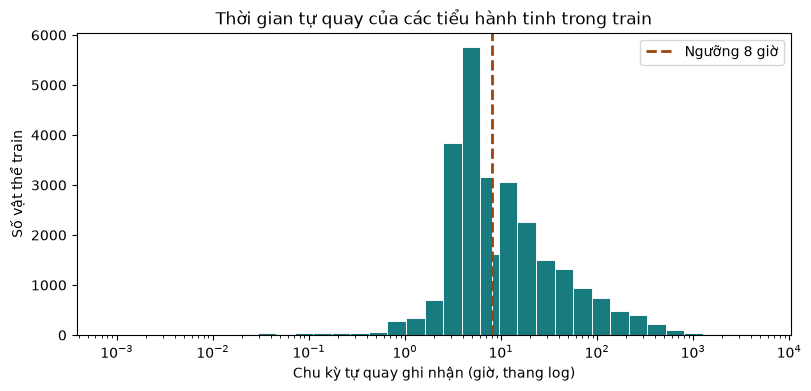

In [11]:
q6_train, q6_test = train_test_split(
    q6_sample, test_size=0.20, random_state=seed, stratify=q6_sample["rot_per"].le(hours)
)
assert set(q6_train["pdes"]).isdisjoint(q6_test["pdes"])
X_train, q6_y_train = q6_train[features], q6_train["rot_per"]
X_test, q6_y_test = q6_test[features], q6_test["rot_per"]
splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
q6_folds = list(splitter.split(X_train, q6_y_train.le(hours)))
print(f"Train: {len(q6_train):,} vật thể | Test: {len(q6_test):,} vật thể")

edges = np.unique(np.r_[np.geomspace(q6_y_train.min(), q6_y_train.max(), 36), hours])
q6_fig, q6_ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
q6_ax.hist(q6_y_train, bins=edges, color="#187b80", edgecolor="white", linewidth=0.65)
q6_ax.axvline(hours, color="#9d420d", linestyle="--", linewidth=2, label="Ngưỡng 8 giờ")
q6_ax.set(xscale="log", xlabel="Chu kỳ tự quay ghi nhận (giờ, thang log)",
       ylabel="Số vật thể train", title="Thời gian tự quay của các tiểu hành tinh trong train")
q6_ax.legend()
plt.show()

## 3. Dùng ba mô hình để đoán số giờ

| Mô hình | Cách dự đoán | Cấu hình thử |
|---|---|---|
| **Linear Regression** | Học đường thẳng trên `log(số giờ)`, rồi dùng `exp` để đoán số giờ dương. | Một cấu hình |
| **KNN** | Tìm vật thể train gần nhất theo đầu vào đã chuẩn hóa và lấy trung bình số giờ của chúng. | 15 hoặc 50 hàng xóm |
| **Random Forest** | Cho nhiều cây đoán số giờ rồi lấy trung bình. | 40 cây, độ sâu tối đa 8 hoặc 14, ít nhất 20 mẫu mỗi lá |

Mỗi mô hình chạy với **bộ gốc** `H, a, e, i` và **bộ có K-Means**. K-Means học ba tâm từ `a, e, i` đã chuẩn hóa. Nó tạo ba cột khoảng cách đến ba tâm, rồi ghép với bốn cột gốc. K-Means chỉ mô tả quỹ đạo theo một cách khác. Ba mô hình hồi quy dùng các cột đó để dự đoán số giờ. [Tài liệu về khoảng cách đến tâm K-Means](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html#sklearn.cluster.KMeans.transform)

`Pipeline` giữ việc học thang chuẩn hóa và tâm cụm bên trong từng lượt huấn luyện. Khi gặp một vật thể validation hoặc test, pipeline dùng lại thang và tâm đã học.

In [12]:
def make_preprocessing(with_clusters):
    branches = [("goc", StandardScaler(), features)]
    if with_clusters:
        distances = Pipeline([
            ("scale_orbit", StandardScaler()),
            ("centers", KMeans(n_clusters=3, n_init=5, random_state=seed)),
            ("scale_distances", StandardScaler()),
        ])
        branches.append(("khoang_cach", distances, orbit))
    return ColumnTransformer(branches)


q6_specs = {
    "Linear Regression": (
        TransformedTargetRegressor(regressor=LinearRegression(), func=np.log, inverse_func=np.exp),
        {},
    ),
    "KNN": (KNeighborsRegressor(), {"model__n_neighbors": [15, 50]}),
    "Random Forest": (
        RandomForestRegressor(n_estimators=40, min_samples_leaf=20, random_state=seed, n_jobs=3),
        {"model__max_depth": [8, 14]},
    ),
}
variants = {"Bộ gốc": False, "Có K-Means": True}

## 4. Chọn mô hình trước khi mở test

Mỗi dự đoán **≤ 8 giờ** được tính là một lượt chọn. **Precision** là tỷ lệ chọn đúng trong những vật thể đã chọn. **Recall** là tỷ lệ tìm được trong tất cả vật thể thực sự đạt điều kiện. **F1** gộp hai tỷ lệ này, nên mô hình cần vừa chọn chính xác vừa tìm đủ nhiều mục tiêu để đạt điểm cao.

Chọn cấu hình có **F1 validation cao nhất**, nếu bằng điểm thì ưu tiên **MAE validation thấp hơn**. MAE là độ lệch tuyệt đối trung bình tính bằng giờ. `GridSearchCV` huấn luyện lại cấu hình thắng trên toàn bộ train. Mô hình dùng cho biểu đồ quyết định được chốt từ sáu kết quả validation. Mốc trung vị dùng để đối chiếu riêng ở phần test.

In [13]:
def score_rotation(estimator, X, y):
    predicted_hours = estimator.predict(X)
    assert np.isfinite(predicted_hours).all()
    return {
        "f1": f1_score(y.le(hours), predicted_hours <= hours, zero_division=0),
        "neg_mae": -mean_absolute_error(y, predicted_hours),
    }


def choose_config(q6_scores):
    f1 = q6_scores["mean_test_f1"]
    neg_mae = q6_scores["mean_test_neg_mae"]
    return max(range(len(f1)), key=lambda q6_idx: (f1[q6_idx], neg_mae[q6_idx]))


q6_searches = {}
validation_rows = []
with threadpool_limits(limits=2):
    for q6_name, (q6_model, q6_grid) in q6_specs.items():
        for q6_variant, with_clusters in variants.items():
            pipeline = Pipeline([
                ("prepare", make_preprocessing(with_clusters)),
                ("model", q6_model),
            ])
            q6_search = GridSearchCV(
                pipeline, q6_grid, cv=q6_folds, scoring=score_rotation,
                refit=choose_config, error_score="raise",
            ).fit(X_train, q6_y_train)
            q6_searches[q6_name, q6_variant] = q6_search.best_estimator_
            q6_idx = q6_search.best_index_
            validation_rows.append({
                "Mô hình": q6_name, "Đầu vào": q6_variant,
                "Cấu hình": str(q6_search.best_params_).replace("model__", "") if q6_grid else "Một cấu hình",
                "F1 validation": q6_search.cv_results_["mean_test_f1"][q6_idx],
                "MAE validation (giờ)": -q6_search.cv_results_["mean_test_neg_mae"][q6_idx],
            })
            print(f"Xong {q6_name} · {q6_variant}")

validation = pd.DataFrame(validation_rows).sort_values(
    ["F1 validation", "MAE validation (giờ)"], ascending=[False, True], kind="stable"
)
q6_selected = tuple(validation.iloc[0][["Mô hình", "Đầu vào"]])
display(validation.round(4))
print(f"Chọn bằng validation: {q6_selected[0]} · {q6_selected[1]}")

Xong Linear Regression · Bộ gốc
Xong Linear Regression · Có K-Means


Xong KNN · Bộ gốc


Xong KNN · Có K-Means


Xong Random Forest · Bộ gốc


Xong Random Forest · Có K-Means


,Mô hình,Đầu vào,Cấu hình,F1 validation,MAE validation (giờ)
1,Linear Regression,Có K-Means,Một cấu hình,0.3924,29.0186
0,Linear Regression,Bộ gốc,Một cấu hình,0.3747,29.0651
2,KNN,Bộ gốc,{'n_neighbors': 15},0.1904,42.2195
3,KNN,Có K-Means,{'n_neighbors': 15},0.1885,42.1701
4,Random Forest,Bộ gốc,{'max_depth': 14},0.0818,40.6538
5,Random Forest,Có K-Means,{'max_depth': 14},0.0782,40.7099


Chọn bằng validation: Linear Regression · Có K-Means


## 5. Chấm test và so với hai mốc

Mỗi mô hình dự đoán một lần trên cùng các vật thể test. Mình cũng dùng `DummyRegressor` để luôn đoán trung vị số giờ của train, rồi áp dụng cùng quy tắc 8 giờ. Mốc chọn ngẫu nhiên cùng số lượng có tỷ lệ đúng kỳ vọng bằng tỷ lệ vật thể thực sự đạt điều kiện trong test.

Cột **Tỷ lệ chọn đúng** là `chọn đúng / đã chọn`. Nếu danh sách trống, tỷ lệ đó để trống. Cột **Bỏ sót** đếm vật thể thật sự quay hết một vòng trong 8 giờ mà mô hình bỏ qua. Khi đọc kết quả, xem cả tỷ lệ đúng và số lượng được chọn.

In [14]:
q6_baseline = DummyRegressor(strategy="median").fit(X_train, q6_y_train)
dummy_key = ("Dummy trung vị", "—")
with threadpool_limits(limits=2):
    predictions = {key: q6_model.predict(X_test) for key, q6_model in q6_searches.items()}
predictions[dummy_key] = q6_baseline.predict(X_test)
actual_fast = q6_y_test.le(hours).to_numpy()
random_precision = actual_fast.mean()
outcomes = {}
q6_score_rows = []
for (q6_name, q6_variant), predicted_hours in predictions.items():
    predicted_fast = predicted_hours <= hours
    tn, fp, fn, tp = confusion_matrix(actual_fast, predicted_fast, labels=[False, True]).ravel()
    outcomes[q6_name, q6_variant] = (tn, fp, fn, tp)
    picks = tp + fp
    q6_score_rows.append({
        "Mô hình": q6_name, "Đầu vào": q6_variant,
        "MAE (giờ)": mean_absolute_error(q6_y_test, predicted_hours),
        "F1": f1_score(actual_fast, predicted_fast, zero_division=0),
        "Đã chọn": picks, "Chọn đúng": tp,
        "Tỷ lệ chọn đúng": tp / picks if picks else np.nan,
        "Recall": tp / (tp + fn),
        "Bỏ sót": fn,
    })

q6_scores = pd.DataFrame(q6_score_rows).set_index(["Mô hình", "Đầu vào"])
display(q6_scores.style.format(
    {"MAE (giờ)": "{:.2f}", "F1": "{:.3f}", "Tỷ lệ chọn đúng": "{:.1%}", "Recall": "{:.1%}"},
    na_rep="—",
))
print(f"Mốc chọn ngẫu nhiên: {random_precision:.1%} tỷ lệ đúng kỳ vọng.")

Mốc chọn ngẫu nhiên: 53.1% tỷ lệ đúng kỳ vọng.


### Hai trường hợp từ tập test

Hình và bảng dùng mô hình đã chọn bằng validation. Bảng ưu tiên một ví dụ chọn đúng và một ví dụ chọn nhầm. Nếu thiếu một trong hai nhóm, bảng lấy nhóm có kết quả khác tiếp theo. So cột dự đoán và cột ghi nhận với 8 giờ để giải thích từng quyết định.

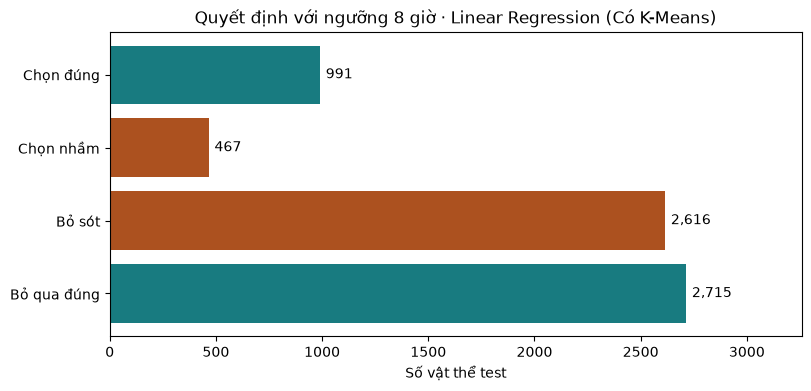

,Kết quả,Mã vật thể,Dự đoán (giờ),Ghi nhận (giờ)
0,Chọn đúng,473825,6.408,5.480
1,Chọn nhầm,111528,7.728,28.709


In [15]:
tn, fp, fn, tp = outcomes[q6_selected]
q6_counts = pd.Series({
    "Chọn đúng": tp, "Chọn nhầm": fp, "Bỏ sót": fn, "Bỏ qua đúng": tn
})
assert q6_counts.sum() == len(q6_test)
q6_fig, q6_ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
bars = q6_ax.barh(q6_counts.index, q6_counts, color=["#187b80", "#ac511f", "#ac511f", "#187b80"])
q6_ax.bar_label(bars, padding=4, fmt=lambda value: f"{value:,.0f}")
q6_ax.invert_yaxis()
q6_ax.set(xlim=(0, q6_counts.max() * 1.2), xlabel="Số vật thể test",
       title=f"Quyết định với ngưỡng 8 giờ · {q6_selected[0]} ({q6_selected[1]})")
plt.show()

predicted_hours = predictions[q6_selected]
predicted_fast = predicted_hours <= hours
q6_examples = pd.DataFrame({
    "Mã vật thể": q6_test["pdes"].to_numpy(),
    "Dự đoán (giờ)": predicted_hours,
    "Ghi nhận (giờ)": q6_y_test.to_numpy(),
    "Kết quả": np.select(
        [predicted_fast & actual_fast, predicted_fast & ~actual_fast, ~predicted_fast & actual_fast],
        ["Chọn đúng", "Chọn nhầm", "Bỏ sót"], default="Bỏ qua đúng",
    ),
})
first_per_outcome = q6_examples.drop_duplicates("Kết quả").set_index("Kết quả")
present_outcomes = [q6_label for q6_label in q6_counts.index if q6_label in first_per_outcome.index]
display(first_per_outcome.loc[present_outcomes[:2]].reset_index().round(3))

## 6. Kết luận để trình bày

Phần đầu trả lời việc chọn mục tiêu có đáng hơn chọn ngẫu nhiên trong mẫu test. Phần sau so hai bộ đầu vào trong **cùng họ mô hình** để xem thêm K-Means thay đổi quyết định ra sao.

In [16]:
winner = q6_scores.loc[q6_selected]
dummy = q6_scores.loc[dummy_key]
picks = tp + fp
if picks:
    precision = winner["Tỷ lệ chọn đúng"]
    delta_pp = 100 * (precision - random_precision)
    random_comparison = (
        f"Tỷ lệ chọn đúng là **{precision:.1%}**, so với **{random_precision:.1%}** kỳ vọng "
        f"nếu chọn ngẫu nhiên cùng số lượng (chênh **{delta_pp:+.1f} điểm phần trăm**)."
    )
else:
    random_comparison = "Danh sách chọn trống nên tỷ lệ chọn đúng không xác định."

family_scores = q6_scores.loc[q6_selected[0]]
base_f1 = family_scores.loc["Bộ gốc", "F1"]
cluster_f1 = family_scores.loc["Có K-Means", "F1"]
display(Markdown(
    f"**{q6_selected[0]} · {q6_selected[1]}** chọn **{picks:,}** trong {len(q6_test):,} vật thể test. "
    f"Có **{tp:,}** vật thể được chọn đúng và **{fn:,}** vật thể đạt điều kiện bị bỏ sót. "
    f"Mô hình tìm được **{winner['Recall']:.1%}** số vật thể thực sự đạt điều kiện. "
    f"{random_comparison}\n\n"
    f"MAE của mô hình là **{winner['MAE (giờ)']:.2f} giờ**, so với "
    f"**{dummy['MAE (giờ)']:.2f} giờ** của mốc trung vị. Mốc trung vị chọn "
    f"**{int(dummy['Đã chọn']):,}** vật thể và có F1 **{dummy['F1']:.3f}**.\n\n"
    f"Với họ {q6_selected[0]}, F1 test từ **{base_f1:.3f}** ở bộ gốc "
    f"thành **{cluster_f1:.3f}** khi thêm K-Means."
))

**Linear Regression · Có K-Means** chọn **1,458** trong 6,789 vật thể test. Có **991** vật thể được chọn đúng và **2,616** vật thể đạt điều kiện bị bỏ sót. Mô hình tìm được **27.5%** số vật thể thực sự đạt điều kiện. Tỷ lệ chọn đúng là **68.0%**, so với **53.1%** kỳ vọng nếu chọn ngẫu nhiên cùng số lượng (chênh **+14.8 điểm phần trăm**).

MAE của mô hình là **29.58 giờ**, so với **29.24 giờ** của mốc trung vị. Mốc trung vị chọn **6,789** vật thể và có F1 **0.694**.

Với họ Linear Regression, F1 test từ **0.365** ở bộ gốc thành **0.391** khi thêm K-Means.

**Kết quả.** Trong lần chạy này, danh sách 1.458 vật thể do mô hình chọn có tỷ lệ đúng 68,0%. Nếu chọn ngẫu nhiên cùng số lượng thì tỷ lệ đúng kỳ vọng là 53,1%. Danh sách của mô hình tìm được 27,5% số vật thể có chu kỳ từ 8 giờ trở xuống. Mốc trung vị có F1 cao hơn vì nó chọn hết tập test, nên tìm được tất cả vật thể đạt điều kiện.

**Phạm vi áp dụng.** Mẫu test gồm các vật thể đã có chu kỳ ghi nhận và ghép được với CSV. Nhóm chưa đo có thể có phân bố khác. Danh sách ở đây ưu tiên theo chu kỳ tự quay. Lên lịch thực tế còn cần vị trí trên bầu trời, độ sáng biểu kiến và thời tiết.

**Cách nói khi vấn đáp.** “Nhóm em muốn biết có thể ước lượng chu kỳ tự quay từ độ sáng và quỹ đạo hay không. Sau khi dự đoán số giờ, nhóm xem trong các vật thể có chu kỳ tối đa 8 giờ, mô hình chọn đúng được bao nhiêu và bỏ sót bao nhiêu.”